# Лабораторна 5. Власне донавчання: генерація SQL за питанням природною мовою (text-to-SQL)

**Що робить цей ноутбук.** Донавчає невелику мовну модель **Qwen3-1.7B** методом **SFT з LoRA**, щоб за схемою таблиць і питанням вона повертала **один SQL-запит і більше нічого**. Модель оцінюється до донавчання (з найкращим промптом, який вдалося скласти) і після нього на **тому самому тестовому наборі зі схемами, яких модель не бачила**.

**Як запускати.** Colab → *Runtime → Change runtime type → T4 GPU* → *Run all*. Усі числа в таблицях і в звіті п. 1.6 **збираються автоматично з вашого запуску**. Фрагменти, що потребують інтерпретації (аналіз помилок, висновок), дописано вручну після перегляду виводу.

**Структура відповідає пунктам завдання:** 1.1 Задача → 1.2 Модель і дані → 1.3 Модель до донавчання → 1.4 Донавчання → 1.5 Порівняння → 1.6 Мій звіт.

In [ ]:
# trl — SFT, peft — LoRA, datasets — дані. bitsandbytes тут не потрібен: ваги 1,7B у fp16 вміщуються в T4 і без квантизації
!pip install -q "transformers>=4.55.0" "trl>=1.17" "peft" "datasets" "accelerate"
# Colab має застарілу бібліотеку torchao, з якою peft не імпортується; для цього проєкту вона не потрібна
!pip uninstall -q -y torchao

In [ ]:
import gc
import json
import os
import random
import re
import sqlite3
import time
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from datasets import Dataset, load_dataset
from IPython.display import Markdown, display
from peft import LoraConfig
from tqdm.auto import tqdm
from transformers import AutoModelForCausalLM, AutoTokenizer, set_seed
from trl import SFTConfig, SFTTrainer

assert torch.cuda.is_available(), "Потрібна GPU: Runtime → Change runtime type → T4 GPU"
SEED = 42
set_seed(SEED)
print(f"GPU: {torch.cuda.get_device_name()}, памʼять: {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB")

GPU: Tesla T4, памʼять: 15.6 GB


## 1.1. Задача

**Що робимо.** Перетворюємо питання природною мовою на SQL-запит до таблиць, схема яких передається разом із питанням (text-to-SQL).

**Хто користувач і як це використовується.** Внутрішній інструмент аналітики: менеджер чи аналітик без знання SQL питає «Скільки замовлень зроблено після 1 січня?», а система повертає запит, який **програма виконує безпосередньо** (від імені користувача БД лише з правом читання) і показує результат у таблиці.

| | |
|---|---|
| **Вхід** | схема у вигляді `CREATE TABLE …` і питання англійською |
| **Вихід** | один SQL-запит `SELECT …`, без пояснень, без Markdown, без `;` в кінці |

**Чому промпту недостатньо і потрібне саме донавчання:**
1. **Жорсткий формат виходу.** Відповідь передається у виконавчий модуль, тож будь-який зайвий текст («Here is the query…»), огорожа ` ```sql ` чи пояснення після запиту ламають виконання. Промпт лише *просить* про формат, але не гарантує його (це вимірюється метрикою «чиста відповідь» нижче).
2. **Конвенції запитів.** Стиль (регістр ключових слів, лапки, відсутність аліасів, форма агрегатів) краще закріпити у вагах, ніж щоразу пояснювати у промпті.
3. **Вартість кожного запиту.** Щоб промптом наблизитися до потрібного результату, потрібні детальні правила й приклади (few-shot). Це сотні токенів на кожен запит. Після донавчання вистачає однієї короткої інструкції.
4. **Чому не RAG.** RAG додає *знання* (документи, факти). Нам же бракує не знань, а *поведінки*: точного формату й стилю відповіді. Схему таблиць ми й так передаємо у вхідних даних.
5. **Приватність і ціна.** Схеми БД бувають конфіденційними. Невелика донавчена модель працює на власному обладнанні (Colab T4 або свій GPU) без відправлення даних стороннім API.

## 1.2. Модель і дані

### Модель: `Qwen/Qwen3-1.7B`
- **Instruct (гібридна post-trained версія), а не `-Base`.** Для чесного порівняння «найкращий промпт проти донавчання» потрібна модель, яка вміє виконувати інструкції з промпту. Base-модель не веде діалог (див. демо 2), тож програла б промпту «задарма». До того ж у instruct-версії вже є шаблон розмови, потрібний для SFT.
- **Розмір 1,7B.** У fp16 це ≈3,4 GB: на T4 (15 GB) залишається багато місця під активації, тому LoRA працює без квантизації. 0,6B замала для запитів із кількома таблицями, а 4B тренується помітно довше й залишає менше запасу памʼяті. Тож 1,7B є компромісом між якістю й часом тренування в безкоштовному Colab.
- **Режим міркувань вимкнено** (`enable_thinking=False`). У продакшені міркування збільшують затримку й вартість, а нам потрібна лише готова відповідь.

### Дані: `b-mc2/sql-create-context`
- **Джерело:** [Hugging Face — b-mc2/sql-create-context](https://huggingface.co/datasets/b-mc2/sql-create-context). Датасет побудовано на основі WikiSQL і Spider: до кожного питання додано `CREATE TABLE`-схему (контекст), яка потрібна для відповіді.
- **Ліцензія:** CC BY 4.0 за карткою датасету. Оскільки дані походять із WikiSQL і Spider, для комерційного використання варто перевірити умови оригінальних датасетів.
- **Формат:** три текстові колонки: `question` (питання), `context` (`CREATE TABLE …`), `answer` (еталонний SQL).
- **Кількість:** десятки тисяч прикладів (точні числа виводить клітинка нижче). Для навчання беремо підмножину: **4000 тренувальних, 200 валідаційних, 500 тестових**.

### Поділ на тренувальний, валідаційний і тестовий набори
Поділ роблю **за схемами** (`context`): усі приклади з однією й тією самою схемою потрапляють лише в один набір. Так модель на тесті стикається з **таблицями, яких не бачила під час тренування**, а це і є реальний сценарій (нова БД). Випадковий поділ за прикладами давав би витік: питання до тієї ж таблиці були б і в train, і в test, а оцінка була б завищеною.

Додатково:
- з датасету прибираю **дублікати** пар (питання, схема);
- відкидаю приклади, **еталонний SQL яких не компілюється в SQLite** на власній схемі (їх неможливо чесно оцінити);
- відкидаю надто довгі діалоги (> 384 токенів), щоб `max_length` не обрізав відповідь.

In [ ]:
MODEL_NAME = "Qwen/Qwen3-1.7B"
N_TRAIN, N_VAL, N_TEST = 4000, 200, 500  # розміри наборів
MAX_LEN = 384                            # максимальна довжина діалогу в токенах; довші приклади відкидаємо
MAX_NEW_TOKENS = 150                     # ліміт генерації відповіді

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

# Коротка інструкція: саме її модель отримуватиме після донавчання
SHORT_SYSTEM = "Translate the question into a SQL query for the given schema. Reply with SQL only."


def user_text(context, question):
    return f"Schema:\n{context}\n\nQuestion: {question}"


def make_messages(context, question, gold=None, system=SHORT_SYSTEM):
    """Діалог system → user → (assistant). Без gold це промпт для інференсу."""
    messages = [
        {"role": "system", "content": system},
        {"role": "user", "content": user_text(context, question)},
    ]
    if gold is not None:
        messages.append({"role": "assistant", "content": gold})
    return messages


def n_tokens(context, question, gold):
    """Довжина всього діалогу (з еталонною відповіддю) в токенах після шаблону розмови."""
    text = tokenizer.apply_chat_template(make_messages(context, question, gold), tokenize=False, enable_thinking=False)
    return len(tokenizer(text)["input_ids"])


def free_memory():
    """Звільняє памʼять GPU."""
    gc.collect()
    torch.cuda.empty_cache()

config.json:   0%|          | 0.00/726 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/9.73k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 11.4MB            

tokenizer.json: downloading bytes:           |  0.00B            

### Допоміжні функції для SQL і метрик

Метрики рахуємо програмно, на тестових прикладах. Для кожної відповіді моделі:
- **Чиста відповідь, %** — відповідь *сама по собі* є одним виконуваним SQL-запитом (без Markdown-огорожі, без пояснень). Це метрика формату: саме така відповідь може піти у виконавчий модуль без обробки.
- **Валідний SQL, %** — після «очищення» (знімаємо `<think>`, огорожу ` ```sql `, пояснення) запит компілюється в SQLite **на схемі цього прикладу**. Перевіряється `EXPLAIN`, тобто чи існують усі таблиці й колонки. Запит не виконується.
- **Точний збіг (EM), %** — очищений запит збігається з еталонним після нормалізації (пробіли, регістр поза лапками, `;`). Це головна метрика якості. Вона **строга**: еквівалентний за змістом запит, написаний інакше, вважається помилкою, тож EM *занижує* справжню якість (див. аналіз помилок).

Чому саме ці метрики: accuracy для генерації тексту не має сенсу, а ці три відповідають практичним вимогам: формат, придатність до виконання, правильність.

In [ ]:
def executes(context, sql):
    """True, якщо SQLite «компілює» запит на схемі context. EXPLAIN будує план запиту, але не виконує його."""
    if not sql or not sql.strip():
        return False
    conn = sqlite3.connect(":memory:")
    try:
        conn.executescript(context)
        conn.execute("EXPLAIN " + sql)
        return True
    except Exception:
        return False
    finally:
        conn.close()


def extract_sql(answer):
    """Дістає SQL із відповіді моделі: знімає <think>, огорожу ```sql, пояснення до й після запиту."""
    text = re.sub(r"(?is)<think>.*?</think>", "", answer).strip()
    fenced = re.search(r"(?is)```(?:sql)?\s*(.*?)```", text)
    if fenced:
        text = fenced.group(1).strip()
    start = re.search(r"(?is)\b(select|with)\b", text)
    if start:
        text = text[start.start():]
    text = text.split("\n\n")[0]  # пояснення після порожнього рядка відкидаємо
    return text.split(";")[0].strip()


def norm_sql(sql):
    """Нормалізація для порівняння: пробіли, регістр поза лапками, лапки, крапка з комою."""
    sql = re.sub(r'"([^"]*)"', r"'\1'", sql.strip().rstrip(";").strip())
    parts = re.split(r"('(?:[^']|'')*')", sql)  # непарні елементи — рядкові літерали, їх не чіпаємо
    out = []
    for i, part in enumerate(parts):
        if i % 2 == 0:
            part = re.sub(r"\s+", " ", part).lower()
            part = re.sub(r"\s*([(),=<>!])\s*", r"\1", part)
        out.append(part)
    return "".join(out).strip()


def mask_literals(sql_normalized):
    """Замінює рядкові й числові літерали на «?»: для виявлення помилок лише в значеннях."""
    sql_normalized = re.sub(r"'(?:[^']|'')*'", "?", sql_normalized)
    return re.sub(r"\b\d+(?:\.\d+)?\b", "?", sql_normalized)


def first_table(context):
    match = re.search(r"(?i)create\s+table\s+[`\"\[]?(\w+)", context)
    return match.group(1) if match else "t"


TYPE_ORDER = ["простий (SELECT … WHERE)", "агрегат", "ORDER BY", "GROUP BY", "JOIN", "підзапит"]


def qtype(sql):
    """Грубий тип запиту за еталонним SQL (для розбивки метрик за складністю)."""
    s = sql.upper()
    if s.count("SELECT") > 1:
        return "підзапит"
    if " JOIN " in s:
        return "JOIN"
    if "GROUP BY" in s:
        return "GROUP BY"
    if "ORDER BY" in s:
        return "ORDER BY"
    if re.search(r"\b(COUNT|SUM|AVG|MIN|MAX)\s*\(", s):
        return "агрегат"
    return "простий (SELECT … WHERE)"


# Самоперевірка функцій на кількох випадках: якщо щось зламано, ноутбук зупиниться тут
_ctx = "CREATE TABLE head (age INTEGER, name VARCHAR); CREATE TABLE dept (id INTEGER)"
assert executes(_ctx, "SELECT COUNT(*) FROM head WHERE age > 56")
assert executes(_ctx, "SELECT age FROM head;")
assert not executes(_ctx, "SELECT salary FROM head"), "колонки salary немає у схемі"
assert not executes(_ctx, "```sql\nSELECT age FROM head\n```"), "огорожа Markdown — не чиста відповідь"
assert not executes(_ctx, "SELECT age FROM head; SELECT 1"), "два запити — не чиста відповідь"
assert extract_sql("```sql\nSELECT age FROM head;\n```\nThis query selects ages.") == "SELECT age FROM head"
assert extract_sql("Here is the query:\nSELECT age FROM head WHERE age > 5;\n\nExplanation: ...") == "SELECT age FROM head WHERE age > 5"
assert norm_sql('SELECT  name FROM head WHERE name = "Bob";') == norm_sql("select name from head where name='Bob'")
assert norm_sql("SELECT x FROM t WHERE n = 'Bob'") != norm_sql("SELECT x FROM t WHERE n = 'bob'"), "регістр у літералах важливий"
assert qtype("SELECT COUNT(*) FROM head") == "агрегат" and qtype("SELECT a FROM t1 AS T1 JOIN t2 AS T2 ON 1=1") == "JOIN"
print("Допоміжні функції пройшли самоперевірку ✅")

Допоміжні функції пройшли самоперевірку ✅


In [ ]:
raw = load_dataset("b-mc2/sql-create-context", split="train")
print(raw)
assert {"question", "context", "answer"} <= set(raw.column_names), f"Неочікувані колонки: {raw.column_names}"
# Якщо датасет недоступний, можна взяти gretelai/synthetic_text_to_sql і перейменувати колонки
# sql_prompt → question, sql_context → context, sql → answer (решта ноутбука не зміниться)

df = raw.to_pandas().rename(columns={"answer": "gold"})[["question", "context", "gold"]]
for column in df.columns:
    df[column] = df[column].str.strip()

n_raw = len(df)
df = df.drop_duplicates(subset=["question", "context"]).reset_index(drop=True)
print(f"\nДо дедуплікації: {n_raw}, після: {len(df)}; унікальних схем: {df['context'].nunique()}")

print("\nКілька прикладів із датасету:\n")
for _, row in df.sample(3, random_state=SEED).iterrows():
    print("Схема:   ", row["context"])
    print("Питання: ", row["question"])
    print("SQL:     ", row["gold"])
    print()

README.md:   0%|          | 0.00/4.43k [00:00<?, ?B/s]

sql_create_context_v4.json: reconstructing file:   0%|          |  0.00B / 21.8MB            

sql_create_context_v4.json: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/78577 [00:00<?, ? examples/s]

Dataset({
    features: ['answer', 'question', 'context'],
    num_rows: 78577
})

До дедуплікації: 78577, після: 78576; унікальних схем: 72947

Кілька прикладів із датасету:

Схема:    CREATE TABLE table_name_94 (chinese_title VARCHAR, album_number VARCHAR)
Питання:  Album # of 5th is what chinese title?
SQL:      SELECT chinese_title FROM table_name_94 WHERE album_number = "5th"

Схема:    CREATE TABLE table_name_1 (engine VARCHAR, rounds VARCHAR, driver VARCHAR, tyres VARCHAR, chassis VARCHAR)
Питання:  What engine was used during the race driven by Jan Lammers using a chassis of d3 d4, making a tyre of g and rounds of 4-6?
SQL:      SELECT engine FROM table_name_1 WHERE tyres = "g" AND chassis = "d3 d4" AND driver = "jan lammers" AND rounds = "4-6"

Схема:    CREATE TABLE table_2454550_1 (most_laps_led VARCHAR, track VARCHAR)
Питання:  Who had most laps led at Chicagoland speedway?
SQL:      SELECT most_laps_led FROM table_2454550_1 WHERE track = "Chicagoland Speedway"



In [ ]:
# Поділ за схемами: приклади з однією схемою потрапляють лише в один набір
contexts = sorted(df["context"].unique())
random.Random(SEED).shuffle(contexts)
n_ctx = len(contexts)
ctx_test = set(contexts[: int(0.15 * n_ctx)])
ctx_val = set(contexts[int(0.15 * n_ctx): int(0.20 * n_ctx)])
ctx_train = set(contexts[int(0.20 * n_ctx):])


def prepare(ctx_set, n, seed):
    """Бере n прикладів зі схем набору; відкидає ті, чий еталон не компілюється або діалог задовгий."""
    pool = df[df["context"].isin(ctx_set)]
    candidates = pool.sample(min(len(pool), int(n * 1.5)), random_state=seed).to_dict("records")
    kept, bad_gold, too_long = [], 0, 0
    for row in candidates:
        if not executes(row["context"], row["gold"]):
            bad_gold += 1
            continue
        row["tokens"] = n_tokens(row["context"], row["question"], row["gold"])
        if row["tokens"] > MAX_LEN:
            too_long += 1
            continue
        row["qtype"] = qtype(row["gold"])
        kept.append(row)
        if len(kept) == n:
            break
    if len(kept) < n:
        print(f"⚠️ Набрано лише {len(kept)} із {n} прикладів")
    return kept, bad_gold, too_long


train_rows, *drop_train = prepare(ctx_train, N_TRAIN, SEED)
val_rows, *drop_val = prepare(ctx_val, N_VAL, SEED)
test_rows, *drop_test = prepare(ctx_test, N_TEST, SEED)
split_rows = {"train": train_rows, "val": val_rows, "test": test_rows}

# Перевірка відсутності витоку: жодна схема не повторюється між наборами
schemas = {name: {r["context"] for r in rows} for name, rows in split_rows.items()}
assert not (schemas["train"] & schemas["val"]), "витік: схеми train і val перетинаються"
assert not (schemas["train"] & schemas["test"]), "витік: схеми train і test перетинаються"
assert not (schemas["val"] & schemas["test"]), "витік: схеми val і test перетинаються"
print("Перевірка витоку: схеми train / val / test не перетинаються ✅")

summary = pd.DataFrame({
    name: {
        "прикладів": len(rows),
        "унікальних схем": len(schemas[name]),
        "середня довжина діалогу, токенів": float(np.mean([r["tokens"] for r in rows])),
    }
    for name, rows in split_rows.items()
}).T
summary = summary.astype({"прикладів": int, "унікальних схем": int})
summary["відкинуто: еталон не компілюється"] = [drop_train[0], drop_val[0], drop_test[0]]
summary["відкинуто: задовгі діалоги"] = [drop_train[1], drop_val[1], drop_test[1]]
display(summary.round(1))

types_table = pd.DataFrame({
    name: pd.Series(Counter(r["qtype"] for r in rows)) for name, rows in split_rows.items()
}).reindex(TYPE_ORDER).fillna(0).astype(int)
print("\nРозподіл типів запитів (за еталонним SQL):")
display(types_table)

Перевірка витоку: схеми train / val / test не перетинаються ✅


,прикладів,унікальних схем,"середня довжина діалогу, токенів",відкинуто: еталон не компілюється,відкинуто: задовгі діалоги
train,4000,3959,99.7,84,0
val,200,199,98.6,5,0
test,500,495,100.8,8,0



Розподіл типів запитів (за еталонним SQL):


,train,val,test
простий (SELECT … WHERE),2769,151,348
агрегат,1082,39,128
ORDER BY,25,2,2
GROUP BY,32,4,2
JOIN,66,2,16
підзапит,26,2,4


In [ ]:
# Дані для SFT у форматі messages (як у демо 3). Колонка chat_template_kwargs вимикає режим міркувань Qwen3
def to_sft_row(row):
    return {
        "messages": make_messages(row["context"], row["question"], row["gold"]),
        "chat_template_kwargs": {"enable_thinking": False},
    }


train_ds = Dataset.from_list([to_sft_row(r) for r in train_rows])
val_ds = Dataset.from_list([to_sft_row(r) for r in val_rows])
print(f"Тренувальний: {len(train_ds)}, валідаційний: {len(val_ds)}, тестовий: {len(test_rows)}")
print("\nПриклад тренувального діалогу:")
for message in train_ds[0]["messages"]:
    print(f"[{message['role']}] {message['content']}")

Тренувальний: 4000, валідаційний: 200, тестовий: 500

Приклад тренувального діалогу:
[system] Translate the question into a SQL query for the given schema. Reply with SQL only.
[user] Schema:
CREATE TABLE table_name_49 (Id VARCHAR)

Question: What is 2011, when 2010 is "WTA Premier 5 Tournaments"?
[assistant] SELECT 2011 FROM table_name_49 WHERE 2010 = "wta premier 5 tournaments"


## 1.3. Модель до донавчання

**Метрики** — ті самі три, що описані вище (чиста відповідь, валідний SQL, точний збіг). Головна — **точний збіг (EM)**.

**Базовий рівень.** Оцінюємо модель із **найкращим промптом, який вдалося скласти**. Щоб вибір промпту був чесним, я порівнюю три варіанти **на валідаційному наборі** (перші 100 прикладів), а найкращий уже запускаю на тесті:
- **P0** — короткий промпт (той самий, що буде після донавчання);
- **P1** — детальні правила: «лише SQL, без пояснень і Markdown, без `;`, ключові слова великими літерами, значення в одинарних лапках»;
- **P2** — ті самі правила **плюс 3 приклади** (few-shot) із тренувального набору.

Для орієнтира додано **тривіальний базовий рівень** `SELECT * FROM <перша таблиця>`: це «нижня межа» за якістю. За побудовою він завжди «чистий» і «валідний», тож порівнювати з ним слід лише за EM.

In [ ]:
def generate_batch(model, conversations, max_new_tokens=MAX_NEW_TOKENS, batch_size=16):
    """Жадібна генерація відповідей на список діалогів (батчами). Повертає список рядків."""
    model.eval()
    answers = []
    for start in tqdm(range(0, len(conversations), batch_size), leave=False):
        chunk = conversations[start:start + batch_size]
        prompts = [
            tokenizer.apply_chat_template(conv, tokenize=False, add_generation_prompt=True, enable_thinking=False)
            for conv in chunk
        ]
        # Для генерації батчем промпти доповнюються зліва, щоб відповіді починалися в одній позиції
        tokenizer.padding_side = "left"
        inputs = tokenizer(prompts, return_tensors="pt", padding=True).to(model.device)
        tokenizer.padding_side = "right"
        with torch.no_grad():
            outputs = model.generate(
                **inputs, max_new_tokens=max_new_tokens, do_sample=False,
                pad_token_id=tokenizer.pad_token_id, use_cache=True,
            )
        new_tokens = outputs[:, inputs["input_ids"].shape[1]:]
        answers += [a.strip() for a in tokenizer.batch_decode(new_tokens, skip_special_tokens=True)]
    return answers


M_CLEAN = "Чиста відповідь, %"
M_VALID = "Валідний SQL, %"
M_EM = "Точний збіг (EM), %"


def score(examples, answers):
    """Оцінює відповіді: повертає список записів із прапорцями clean / valid / em."""
    records = []
    for example, answer in zip(examples, answers):
        sql = extract_sql(answer)
        records.append({
            **example,
            "answer": answer,
            "sql": sql,
            "clean": executes(example["context"], answer),   # відповідь сама є одним виконуваним запитом
            "valid": executes(example["context"], sql),      # після очищення запит компілюється на схемі
            "em": norm_sql(sql) == norm_sql(example["gold"]),
        })
    return records


def summarize(records):
    n = len(records)
    return {
        M_CLEAN: 100 * sum(r["clean"] for r in records) / n,
        M_VALID: 100 * sum(r["valid"] for r in records) / n,
        M_EM: 100 * sum(r["em"] for r in records) / n,
    }


# Варіанти промптів
P0 = "P0 · короткий промпт"
P1 = "P1 · детальні правила"
P2 = "P2 · правила + 3 приклади"
VARIANTS = [P0, P1, P2]

RULES_PROMPT = (
    "You are a text-to-SQL translator. You get a database schema (CREATE TABLE statements) and a question. "
    "Reply with exactly one SQL SELECT query that answers the question, using only tables and columns from the schema. "
    "Output the bare query only: no explanations, no comments, no markdown code fences, no trailing semicolon. "
    "Write SQL keywords in uppercase, keep column names exactly as in the schema, and put string values in single quotes."
)


def pick_shots(rows):
    """Три тренувальні приклади різних типів для few-shot промпту."""
    shots = []
    for wanted in ["простий (SELECT … WHERE)", "агрегат", "ORDER BY"]:
        row = next((r for r in rows if r["qtype"] == wanted), None)
        if row is not None:
            shots.append(row)
    return shots or rows[:3]


FEW_SHOTS = pick_shots(train_rows)


def build_conv(row, variant):
    """Діалог-промпт для прикладу залежно від варіанта промпту."""
    if variant == P0:
        conv = [{"role": "system", "content": SHORT_SYSTEM}]
    else:
        conv = [{"role": "system", "content": RULES_PROMPT}]
    if variant == P2:
        for shot in FEW_SHOTS:
            conv.append({"role": "user", "content": user_text(shot["context"], shot["question"])})
            conv.append({"role": "assistant", "content": shot["gold"]})
    conv.append({"role": "user", "content": user_text(row["context"], row["question"])})
    return conv


def run_eval(model, examples, variant):
    """Генерує відповіді з промптом variant і оцінює їх."""
    answers = generate_batch(model, [build_conv(r, variant) for r in examples])
    return score(examples, answers)


def avg_prompt_tokens(variant, rows=test_rows[:50]):
    """Середня довжина промпта (без відповіді) в токенах: показує вартість кожного запиту."""
    lengths = [
        len(tokenizer(tokenizer.apply_chat_template(
            build_conv(r, variant), tokenize=False, add_generation_prompt=True, enable_thinking=False))["input_ids"])
        for r in rows
    ]
    return float(np.mean(lengths))

In [ ]:
model = AutoModelForCausalLM.from_pretrained(MODEL_NAME, dtype=torch.float16, device_map="auto")
print(f"{MODEL_NAME}: {model.num_parameters() / 1e9:.2f} млрд параметрів, памʼять GPU після завантаження: {torch.cuda.memory_allocated() / 1e9:.1f} GB")

# 1) Вибір найкращого промпту на ВАЛІДАЦІЙНОМУ наборі (тест не використовуємо)
VAL_SUBSET = val_rows[:100]
val_results = {}
for variant in VARIANTS:
    t0 = time.time()
    val_results[variant] = summarize(run_eval(model, VAL_SUBSET, variant))
    val_results[variant]["хв"] = (time.time() - t0) / 60
val_prompt_table = pd.DataFrame(val_results).T
display(val_prompt_table.round(1))

best_variant = max(VARIANTS, key=lambda v: (val_results[v][M_EM], val_results[v][M_VALID], val_results[v][M_CLEAN]))
print(f"\nНайкращий промпт за EM на валідації: {best_variant}")

model.safetensors.index.json:   0%|          | 0.00/25.6k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/311 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

Qwen/Qwen3-1.7B: 1.72 млрд параметрів, памʼять GPU після завантаження: 3.4 GB


  0%|          | 0/7 [00:00<?, ?it/s]

  0%|          | 0/7 [00:00<?, ?it/s]

  0%|          | 0/7 [00:00<?, ?it/s]

,"Чиста відповідь, %","Валідний SQL, %","Точний збіг (EM), %",хв
P0 · короткий промпт,97.0,97.0,24.0,0.4
P1 · детальні правила,99.0,99.0,22.0,0.3
P2 · правила + 3 приклади,99.0,99.0,27.0,0.3



Найкращий промпт за EM на валідації: P2 · правила + 3 приклади


In [ ]:
# 2) Оцінка на ТЕСТОВОМУ наборі: найкращий промпт і (для чесного порівняння з донавченою моделлю) короткий P0
before = {}
for variant in dict.fromkeys([P0, best_variant]):
    before[variant] = run_eval(model, test_rows, variant)

trivial_records = score(test_rows, [f"SELECT * FROM {first_table(r['context'])}" for r in test_rows])

tokens_p0 = avg_prompt_tokens(P0)
tokens_best = avg_prompt_tokens(best_variant)

rows_before = {"Тривіальний базовий рівень: SELECT * FROM <перша таблиця>": summarize(trivial_records)}
for variant, records in before.items():
    rows_before[f"Qwen3-1.7B до донавчання · {variant}"] = summarize(records)
before_table = pd.DataFrame(rows_before).T
display(before_table.round(1))
print(f"Середня довжина промпта: P0 — {tokens_p0:.0f} токенів, {best_variant} — {tokens_best:.0f} токенів")

  0%|          | 0/32 [00:00<?, ?it/s]

  0%|          | 0/32 [00:00<?, ?it/s]

,"Чиста відповідь, %","Валідний SQL, %","Точний збіг (EM), %"
Тривіальний базовий рівень: SELECT * FROM <перша таблиця>,100.0,100.0,0.0
Qwen3-1.7B до донавчання · P0 · короткий промпт,95.6,95.8,28.6
Qwen3-1.7B до донавчання · P2 · правила + 3 приклади,98.2,98.2,29.6


Середня довжина промпта: P0 — 74 токенів, P2 · правила + 3 приклади — 355 токенів


In [ ]:
def show_examples(records, k=8, title=""):
    """Друкує k прикладів: питання, еталон і відповідь моделі."""
    print(title)
    for r in records[:k]:
        mark = "✅" if r["em"] else "❌"
        print(f"{mark} Питання: {r['question']}")
        print(f"   Еталон:  {r['gold']}")
        print(f"   Модель:  {r['answer']}".replace("\n", "\n            "))
        print()


show_examples(before[best_variant], k=8, title=f"Відповіді моделі ДО донавчання ({best_variant}), перші 8 тестових прикладів:\n")

Відповіді моделі ДО донавчання (P2 · правила + 3 приклади), перші 8 тестових прикладів:

✅ Питання: What is the Tenure of the Officer who died in a helicopter accident with Badge/Serial Number 16805?
   Еталон:  SELECT tenure FROM table_name_95 WHERE cause_of_death = "helicopter accident" AND badge_serial_number = "16805"
   Модель:  SELECT tenure FROM table_name_95 WHERE cause_of_death = "helicopter accident" AND badge_serial_number = "16805"

❌ Питання: Which of the entrants had Luigi Fagioli as a driver?
   Еталон:  SELECT entrant FROM table_name_79 WHERE driver = "luigi fagioli"
   Модель:  SELECT entrant FROM table_name_79 WHERE driver = "Luigi Fagioli"

✅ Питання: what is the result when extra is 4 x 100 m relay and the year is later than 1971?
   Еталон:  SELECT result FROM table_name_15 WHERE extra = "4 x 100 m relay" AND year > 1971
   Модель:  SELECT result FROM table_name_15 WHERE extra = "4 x 100 m relay" AND year > 1971

❌ Питання: How many deciles have a Gender of coed, a

## 1.4. Донавчання

**Метод: SFT з LoRA** (бібліотеки TRL і PEFT, як у демо 3).
- *Чому не повне донавчання:* для 1,7B воно потребує близько 16 байтів на параметр, тобто ≈28 GB, а T4 має 15 GB.
- *Чому не QLoRA:* ваги 1,7B у fp16 займають лише ≈3,4 GB і вміщуються без квантизації. Тоді квантизація зайва: QLoRA повільніша через деквантизацію й додає похибку.
- *Чому не DPO:* у нас немає пар «краща/гірша відповідь», є лише еталонні відповіді, тож це задача для SFT.

**Гіперпараметри та їх обґрунтування:**

| Параметр | Значення | Чому |
|---|---|---|
| `r` / `lora_alpha` | 16 / 32 | ранг 16 дає достатньо «свободи» адаптеру для вузької задачі; `alpha = 2·r` — типове масштабування |
| `lora_dropout` | 0,05 | легка регуляризація адаптера |
| `target_modules` | `all-linear` | адаптери в усіх лінійних шарах (attention + MLP) дають кращу якість, ніж лише в attention |
| `learning_rate` | 2e-4 | для LoRA приблизно в 10 разів більший, ніж для повного донавчання (там 2e-5) |
| розклад LR | cosine, warmup 20 кроків | плавне зменшення швидкості навчання в кінці; розігрів уникає різкого початку |
| `max_steps` | 400 | ефективний батч 8 → 3200 прикладів, це ≈0,8 епохи з 4000. Для вузької задачі цього достатньо; перенавчання відстежуємо за validation loss |
| батч | 4 × 2 (накопичення градієнта) = 8 | вміщується в памʼять T4 |
| `max_length` | 384 | усі діалоги після фільтрації коротші; нічого не обрізається |
| `assistant_only_loss` | `True` | loss лише на відповіді асистента (SQL), а не на схемі й питанні (див. питання 29) |
| `fp16`, gradient checkpointing | так | T4 не підтримує bf16; чекпойнтинг активацій економить памʼять коштом швидкості |
| `eval_steps` | 25 | кожні 25 кроків рахуємо validation loss, щоб помітити перенавчання |

In [ ]:
peft_config = LoraConfig(
    r=16,
    lora_alpha=32,
    lora_dropout=0.05,
    target_modules="all-linear",
    task_type="CAUSAL_LM",
)

sft_config = SFTConfig(
    output_dir="qwen3-1.7b-text2sql-lora",
    max_length=MAX_LEN,
    per_device_train_batch_size=4,
    gradient_accumulation_steps=2,   # ефективний розмір батча: 4 × 2 = 8 прикладів
    per_device_eval_batch_size=8,
    learning_rate=2e-4,
    lr_scheduler_type="cosine",
    warmup_steps=20,
    max_steps=400,
    eval_strategy="steps",
    eval_steps=25,
    fp16=True,
    gradient_checkpointing=True,
    gradient_checkpointing_kwargs={"use_reentrant": False},
    assistant_only_loss=True,
    logging_steps=25,
    save_strategy="no",
    report_to="none",
    seed=SEED,
)

free_memory()
torch.cuda.reset_peak_memory_stats()
trainer = SFTTrainer(
    model=model,
    args=sft_config,
    train_dataset=train_ds,
    eval_dataset=val_ds,
    processing_class=tokenizer,
    peft_config=peft_config,
)
trainer.model.print_trainable_parameters()

start = time.time()
trainer.train()
train_minutes = (time.time() - start) / 60
peak_gb = torch.cuda.max_memory_allocated() / 1e9
print(f"\nТривалість тренування: {train_minutes:.1f} хв; пікова памʼять GPU: {peak_gb:.1f} GB")

Tokenizing train dataset:   0%|          | 0/4000 [00:00<?, ? examples/s]

Building labels for train dataset:   0%|          | 0/4000 [00:00<?, ? examples/s]

Truncating train dataset:   0%|          | 0/4000 [00:00<?, ? examples/s]

Dropping fully masked examples from train dataset:   0%|          | 0/4000 [00:00<?, ? examples/s]

Tokenizing eval dataset:   0%|          | 0/200 [00:00<?, ? examples/s]

Building labels for eval dataset:   0%|          | 0/200 [00:00<?, ? examples/s]

Truncating eval dataset:   0%|          | 0/200 [00:00<?, ? examples/s]

Dropping fully masked examples from eval dataset:   0%|          | 0/200 [00:00<?, ? examples/s]

trainable params: 17,432,576 || all params: 1,738,007,552 || trainable%: 1.0030


Step,Training Loss,Validation Loss,Entropy,Mean Token Accuracy,Num Tokens
25,0.814204,0.104197,0.107519,0.970171,19996.000000
50,0.089344,0.084811,0.073542,0.976529,39747.000000
75,0.090527,0.072963,0.060841,0.977664,59609.000000
100,0.069020,0.060611,0.055720,0.981094,79207.000000
125,0.071736,0.051547,0.051386,0.985015,99034.000000
150,0.061593,0.039917,0.039133,0.987537,119887.000000
175,0.047804,0.040648,0.051325,0.987793,139856.000000
200,0.049700,0.035910,0.035781,0.989939,159861.000000
225,0.035162,0.033285,0.031170,0.990165,179774.000000
250,0.044069,0.033099,0.033927,0.990446,199583.000000



Тривалість тренування: 9.8 хв; пікова памʼять GPU: 4.0 GB


,train loss,val loss
крок,,
25,0.8142,0.1042
50,0.0893,0.0848
75,0.0905,0.0730
100,0.0690,0.0606
125,0.0717,0.0515
150,0.0616,0.0399
175,0.0478,0.0406
200,0.0497,0.0359
225,0.0352,0.0333


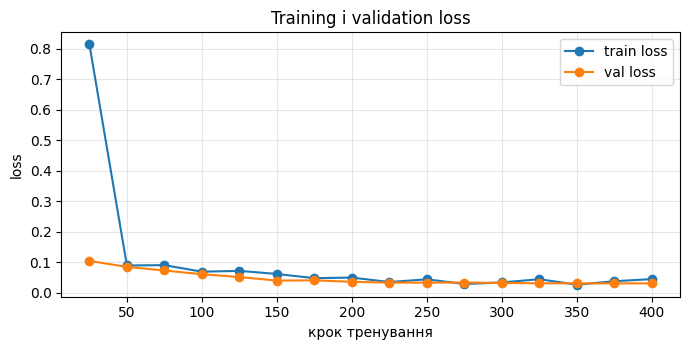

Ознак перенавчання немає: val loss 0.0307 в кінці (мінімум 0.0307 на кроці 400).


In [ ]:
# Training і validation loss за кроками (з trainer.state.log_history)
log = trainer.state.log_history
train_df = pd.DataFrame([{"крок": h["step"], "train loss": h["loss"]} for h in log if "loss" in h])
val_df = pd.DataFrame([{"крок": h["step"], "val loss": h["eval_loss"]} for h in log if "eval_loss" in h])
loss_df = train_df.merge(val_df, on="крок", how="outer").sort_values("крок").set_index("крок")
display(loss_df.round(4))

fig, ax = plt.subplots(figsize=(7, 3.6))
loss_df.plot(ax=ax, marker="o", title="Training і validation loss")
ax.set_xlabel("крок тренування")
ax.set_ylabel("loss")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Автоматична перевірка на перенавчання: val loss мав мінімум раніше, ніж в кінці, і потім виріс більш ніж на 10%
best_step = int(val_df.loc[val_df["val loss"].idxmin(), "крок"])
min_val = float(val_df["val loss"].min())
last_step = int(val_df["крок"].iloc[-1])
last_val = float(val_df["val loss"].iloc[-1])
overfit = best_step < last_step and last_val > 1.10 * min_val
if overfit:
    print(f"⚠️ Ознаки перенавчання: мінімум val loss {min_val:.4f} на кроці {best_step}, на кроці {last_step} він {last_val:.4f}.")
else:
    print(f"Ознак перенавчання немає: val loss {last_val:.4f} в кінці (мінімум {min_val:.4f} на кроці {best_step}).")

**Перенавчання не помічено, гіперпараметри не змінювалися.** Validation loss знижувався протягом усього тренування (0,104 на кроці 25 → 0,0307 на кроці 400) і виходить на плато: 0,0310 → 0,0308 → 0,0308 → 0,0307 на кроках 325–400. Train loss на кроках 225–400 коливається в межах 0,026–0,045 (це середні по 25 кроках, тож він шумний) і того самого порядку, що й validation loss, тобто розриву між ними немає. Автоматична перевірка теж не виявила ознак перенавчання. Тренування було коротшим за одну епоху (400 кроків × 8 = 3200 прикладів із 4000), тож кожен приклад модель бачила не більше одного разу, а це ускладнює перенавчання.

## 1.5. Порівняння до і після донавчання

Усе оцінюється на **тих самих 500 тестових прикладах** (схеми яких не було в тренуванні). Донавчена модель отримує **короткий промпт P0**, а модель «до» і з коротким, і з найкращим промптом.

In [ ]:
after_records = run_eval(trainer.model, test_rows, P0)
tokens_after = tokens_p0  # після донавчання використовується той самий короткий промпт P0

rows_all = dict(rows_before)
rows_all["Qwen3-1.7B після донавчання (LoRA) · P0 короткий промпт"] = summarize(after_records)
compare_table = pd.DataFrame(rows_all).T
compare_table["токенів у промпті"] = [np.nan, tokens_p0] + ([tokens_best] if best_variant != P0 else []) + [tokens_after]
display(compare_table.round(1))

# Розбивка EM за типами запитів: до (найкращий промпт) і після
def em_by_type(records):
    return pd.DataFrame(records).groupby("qtype")["em"].mean() * 100


type_table = pd.DataFrame({
    "прикладів": pd.Series(Counter(r["qtype"] for r in test_rows)),
    "EM до, %": em_by_type(before[best_variant]),
    "EM після, %": em_by_type(after_records),
}).reindex(TYPE_ORDER).dropna(subset=["прикладів"])
type_table["прикладів"] = type_table["прикладів"].astype(int)
print("\nEM за типами запитів:")
display(type_table.round(1))

  0%|          | 0/32 [00:00<?, ?it/s]

,"Чиста відповідь, %","Валідний SQL, %","Точний збіг (EM), %",токенів у промпті
Тривіальний базовий рівень: SELECT * FROM <перша таблиця>,100.0,100.0,0.0,NaN
Qwen3-1.7B до донавчання · P0 · короткий промпт,95.6,95.8,28.6,74.2
Qwen3-1.7B до донавчання · P2 · правила + 3 приклади,98.2,98.2,29.6,355.2
Qwen3-1.7B після донавчання (LoRA) · P0 короткий промпт,98.6,98.6,77.4,74.2



EM за типами запитів:


,прикладів,"EM до, %","EM після, %"
простий (SELECT … WHERE),348,38.5,83.3
агрегат,128,9.4,71.9
ORDER BY,2,100.0,100.0
GROUP BY,2,0.0,0.0
JOIN,16,0.0,18.8
підзапит,4,0.0,0.0


In [ ]:
# Ті самі приклади, що й у розділі 1.3: до і після
print("ПІСЛЯ донавчання, ті самі 8 тестових прикладів:\n")
for before_rec, after_rec in zip(before[best_variant][:8], after_records[:8]):
    print(f"Питання: {before_rec['question']}")
    print(f"  Еталон:  {before_rec['gold']}")
    print(f"  ДО  {'✅' if before_rec['em'] else '❌'}: " + before_rec["answer"].replace("\n", " ⏎ "))
    print(f"  ПІСЛЯ {'✅' if after_rec['em'] else '❌'}: " + after_rec["answer"].replace("\n", " ⏎ "))
    print()

ПІСЛЯ донавчання, ті самі 8 тестових прикладів:

Питання: What is the Tenure of the Officer who died in a helicopter accident with Badge/Serial Number 16805?
  Еталон:  SELECT tenure FROM table_name_95 WHERE cause_of_death = "helicopter accident" AND badge_serial_number = "16805"
  ДО  ✅: SELECT tenure FROM table_name_95 WHERE cause_of_death = "helicopter accident" AND badge_serial_number = "16805"
  ПІСЛЯ ✅: SELECT tenure FROM table_name_95 WHERE cause_of_death = "helicopter accident" AND badge_serial_number = "16805"

Питання: Which of the entrants had Luigi Fagioli as a driver?
  Еталон:  SELECT entrant FROM table_name_79 WHERE driver = "luigi fagioli"
  ДО  ❌: SELECT entrant FROM table_name_79 WHERE driver = "Luigi Fagioli"
  ПІСЛЯ ✅: SELECT entrant FROM table_name_79 WHERE driver = "luigi fagioli"

Питання: what is the result when extra is 4 x 100 m relay and the year is later than 1971?
  Еталон:  SELECT result FROM table_name_15 WHERE extra = "4 x 100 m relay" AND year > 1971
  

### Аналіз помилок донавченої моделі
Клітинка нижче автоматично розподіляє помилки (EM = ❌) за видами й показує приклади, щоб було що аналізувати «очима».

In [ ]:
def error_kind(record):
    """Грубе визначення виду помилки донавченої моделі."""
    if not record["valid"]:
        return "SQL не виконується на схемі (вигадана колонка/таблиця або синтаксис)"
    predicted, gold = norm_sql(record["sql"]), norm_sql(record["gold"])
    if mask_literals(predicted) == mask_literals(gold):
        return "Структура збігається, відрізняються лише значення (літерали)"
    tokens = lambda s: Counter(re.findall(r"\w+|[^\w\s]", s))
    if tokens(predicted) == tokens(gold):
        return "Ті самі токени в іншому порядку (можливо, еквівалентний запит)"
    return "Інша структура: інші колонки, функції чи умови"


errors = [r for r in after_records if not r["em"]]
print(f"Помилок після донавчання: {len(errors)} із {len(after_records)} ({100 * len(errors) / len(after_records):.1f}%)\n")
error_kinds = Counter(error_kind(r) for r in errors)
error_table = pd.DataFrame({"кількість": pd.Series(error_kinds)}).sort_values("кількість", ascending=False)
if len(errors):
    error_table["частка помилок, %"] = 100 * error_table["кількість"] / len(errors)
display(error_table.round(1))

print("\nПриклади помилок (до 8):\n")
for r in errors[:8]:
    print(f"[{error_kind(r)}]")
    print(f"  Схема:   {r['context'][:200]}")
    print(f"  Питання: {r['question']}")
    print(f"  Еталон:  {r['gold']}")
    print(f"  Модель:  {r['sql']}")
    print()

Помилок після донавчання: 113 із 500 (22.6%)



,кількість,"частка помилок, %"
"Інша структура: інші колонки, функції чи умови",55,48.7
"Структура збігається, відрізняються лише значення (літерали)",46,40.7
SQL не виконується на схемі (вигадана колонка/таблиця або синтаксис),7,6.2
"Ті самі токени в іншому порядку (можливо, еквівалентний запит)",5,4.4



Приклади помилок (до 8):

[Структура збігається, відрізняються лише значення (літерали)]
  Схема:   CREATE TABLE table_name_48 (result VARCHAR, role_episode VARCHAR, year VARCHAR)
  Питання: What result has outstanding achievement in drama, as the role/episode with a year prior to 1995?
  Еталон:  SELECT result FROM table_name_48 WHERE role_episode = "outstanding achievement in drama" AND year < 1995
  Модель:  SELECT result FROM table_name_48 WHERE role_episode = "drama" AND year < 1995

[Інша структура: інші колонки, функції чи умови]
  Схема:   CREATE TABLE table_name_90 (gold INTEGER, bronze VARCHAR, total VARCHAR, rank VARCHAR)
  Питання: What is the average gold total for nations ranked 6 with 1 total medal and 1 bronze medal?
  Еталон:  SELECT AVG(gold) FROM table_name_90 WHERE total = 1 AND rank = "6" AND bronze > 1
  Модель:  SELECT AVG(gold) FROM table_name_90 WHERE total = 1 AND rank = 6 AND bronze = 1

[Структура збігається, відрізняються лише значення (літерали)]
  Схема:

**Аналіз помилок донавченої моделі** (за виводом вище)

**Загальна картина.** Помилок EM: 113 із 500 (22,6%), тобто EM = 77,4%. За видами: 55 (48,7%) — інша структура (інші колонки, функції чи умови); 46 (40,7%) — структура збігається, відрізняються лише значення (літерали); 7 (6,2%) — SQL не виконується на схемі; 5 (4,4%) — ті самі токени в іншому порядку.

**Які типи запитів гірші.** Найкраще модель розв'язує прості `SELECT … WHERE` (EM 83,3% проти 38,5% до донавчання), гірше агрегати (71,9% проти 9,4%), ще гірше `JOIN` (18,8%, було 0%) і підзапити (0 із 4); `GROUP BY` — 0 із 2, `ORDER BY` — 2 із 2. Важливе застереження: складні типи в тесті представлені дуже малою кількістю прикладів (`ORDER BY` — 2, `GROUP BY` — 2, `JOIN` — 16, підзапит — 4), тож ці відсотки статистично ненадійні. У тренувальній вибірці їх теж мало (25, 32, 66 і 26 із 4000), бо датасет здебільшого складається з простих запитів до однієї таблиці (WikiSQL). Тобто слабкий результат на `JOIN` і підзапитах пояснюється нестачею таких прикладів у навчанні, а цей тест ще й погано їх перевіряє.

**Причини помилок за 8 переглянутими прикладами** (з 113; це лише вибірка, і 7 запитів, що не виконуються, серед них не було):
1. **Одна реальна помилка моделі.** На питання «What result has outstanding achievement in drama…» еталон `role_episode = "outstanding achievement in drama"`, а модель скоротила значення до `"drama"`, тобто загубила частину літерала.
2. **Неоднозначність питання або шум еталона у 5 випадках.** Вибір агрегату у WikiSQL-питаннях неочевидний: на «Which Seat has a Season 6 of…» еталон `MAX(seat)`, модель `SUM(seat)`; на «How many gold medals does each school…» еталон просто вибирає колонку, а модель додала `COUNT`. На «only 751 in attendance» еталон `attendance < 751`, модель `= 751` (розумніше читання). У питанні про «1 total medal and 1 bronze medal» еталон містить `bronze > 1`, що суперечить питанню, а модель написала `bronze = 1`. Ще один еталон має артефакт обробки WikiSQL: `MAX(sales), _receipts, _or_shipments__$1, 000 AS _`.
3. **Формальні відмінності запису у 2 випадках.** Еталон `losses = 0`, модель `losses = "0"` (для колонки `VARCHAR` у SQLite це майже напевно дає той самий результат). В іншому прикладі питання містило **тонкий пробіл U+2009** (`1333 mhz`), модель точно скопіювала його в літерал, а еталон має звичайний пробіл, тож у виводі рядки виглядають однаково, але EM їх розрізняє. Це недолік моєї нормалізації: Unicode-пробіли в літералах варто зводити до звичайних.

Отже, серед переглянутих помилок очевидним промахом моделі є лише один скорочений літерал. Окремо лишаються 7 запитів (1,4% тесту), що не виконуються на схемі (вигадана колонка чи синтаксис): це справжні помилки, які я не розглядав детально.

**Що саме змінило донавчання.** До донавчання (P2) із перших 8 тестових прикладів хибними були 3 (№2, №4 і №6). Причини: регістр літералів (`"Luigi Fagioli"` замість `"luigi fagioli"`, `"World Championships"`), число в лапках (`year > '2007'`) і вибір агрегату (`COUNT(*)` замість `SUM`). Усе це **конвенції датасету**: еталонні літерали записані малими літерами, числа без лапок. Після донавчання ці 3 приклади (як і решта з перших 8) розв'язані правильно, тож модель вивчила конвенції.

**Висновок щодо метрики.** Оскільки значна частина «помилок» є неоднозначністю чи форматом запису, EM 77,4% — це нижня оцінка. Точнішу оцінку дала б **execution accuracy**, тобто порівняння результатів виконання на заповнених таблицях.

### Чи не погіршилася модель у загальних запитах поза задачею?
Адаптер LoRA змінює поведінку моделі, тож перевіряємо, чи вона не «забула» загальні вміння й чи не відповідає SQL на запити, які SQL не стосуються. Той самий об'єкт моделі використовується двічі: з **вимкненим адаптером** (стан «до», `disable_adapter()`) і зі **ввімкненим** (стан «після»). Автоматичні перевірки прості (ключові слова, мова відповіді), тому тексти відповідей варто прочитати.

In [ ]:
def cyrillic_share(text):
    letters = re.findall(r"[A-Za-zА-Яа-яІіЇїЄєҐґ]", text)
    cyrillic = re.findall(r"[А-Яа-яІіЇїЄєҐґ]", text)
    return len(cyrillic) / max(1, len(letters))


def looks_like_sql(text):
    return bool(re.match(r"(?is)\s*(```sql\s*)?(select|with)\b", text))


GENERAL = [  # (запит, перевірка правильності, що перевіряємо)
    ("Що таке фотосинтез? Поясни двома реченнями українською.", lambda a: cyrillic_share(a) > 0.5, "відповідь українською"),
    ("What is the capital of France? Answer in one sentence.", lambda a: "paris" in a.lower(), "згадує Paris"),
    ("Write a Python function that reverses a string.", lambda a: "def " in a and ("[::-1]" in a or "reversed" in a), "функція, що розвертає рядок"),
    ("Translate to Ukrainian: 'Good morning, how are you?'", lambda a: cyrillic_share(a) > 0.3, "переклад кирилицею"),
    ("What is 17 * 23?", lambda a: "391" in a, "правильна відповідь 391"),
    ("Give me three short tips for a healthy sleep.", lambda a: len(a) > 40 and not looks_like_sql(a), "змістовна порада, не SQL"),
]
general_conversations = [[{"role": "user", "content": q}] for q, _, _ in GENERAL]

with trainer.model.disable_adapter():  # стан «до»: адаптер вимкнено
    general_before = generate_batch(trainer.model, general_conversations, max_new_tokens=200, batch_size=6)
general_after = generate_batch(trainer.model, general_conversations, max_new_tokens=200, batch_size=6)  # адаптер увімкнено

general_rows = []
for (question, check, what), a_before, a_after in zip(GENERAL, general_before, general_after):
    general_rows.append({
        "запит": question[:48] + ("…" if len(question) > 48 else ""),
        "перевірка": what,
        "до: ок": check(a_before),
        "після: ок": check(a_after),
        "після: відповів SQL-ом": looks_like_sql(a_after),
    })
general_table = pd.DataFrame(general_rows)
display(general_table)
ok_before = int(general_table["до: ок"].sum())
ok_after = int(general_table["після: ок"].sum())
sql_leaks = int(general_table["після: відповів SQL-ом"].sum())
print(f"Пройдено перевірок: до — {ok_before} з {len(GENERAL)}, після — {ok_after} з {len(GENERAL)}; відповідей SQL-ом на несхожі запити: {sql_leaks}\n")

for (question, _, _), a_before, a_after in zip(GENERAL, general_before, general_after):
    print(f"Запит: {question}")
    print(f"  ДО:    {a_before[:300]}".replace("\n", " ⏎ "))
    print(f"  ПІСЛЯ: {a_after[:300]}".replace("\n", " ⏎ "))
    print()

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

,запит,перевірка,до: ок,після: ок,після: відповів SQL-ом
0,Що таке фотосинтез? Поясни двома реченнями украї…,відповідь українською,True,True,False
1,What is the capital of France? Answer in one sen…,згадує Paris,True,True,False
2,Write a Python function that reverses a string.,"функція, що розвертає рядок",True,True,False
3,"Translate to Ukrainian: 'Good morning, how are y…",переклад кирилицею,True,True,False
4,What is 17 * 23?,правильна відповідь 391,True,True,False
5,Give me three short tips for a healthy sleep.,"змістовна порада, не SQL",True,True,False


Пройдено перевірок: до — 6 з 6, після — 6 з 6; відповідей SQL-ом на несхожі запити: 0

Запит: Що таке фотосинтез? Поясни двома реченнями українською.
  ДО:    Фотосинтез — це процес, за допомогою якого рослини, алгебри та інші організми конвертуєть сонячну енергію в хімічну. Цей процес відбувається в хлоропластах і дозволяє організмам створювати їжу і відновлювати атмосферність.
  ПІСЛЯ: Фотосинтез — це процес, за яким рослини, бактерії та інші організми виконують розщеплення молекул повітряного кисню, щоб створити енергію для росту та розвитку. Цей процес відбувається в хлоропластах, де рослини використовують сонячну енергію для створення глюкози та кисню.

Запит: What is the capital of France? Answer in one sentence.
  ДО:    The capital of France is Paris.
  ПІСЛЯ: The capital of France is Paris.

Запит: Write a Python function that reverses a string.
  ДО:    Sure! Here's a simple Python function that reverses a string: ⏎  ⏎ ```python ⏎ def reverse_string(s): ⏎     return s[::-1] ⏎

**Результат перевірки.** Автоматичні перевірки пройдено **6 з 6 і до, і після** донавчання, відповідей SQL-ом на несхожі запити **немає** (0 із 6). Проте за текстами видно **зсув у бік лаконічності**: на запит про Python до донавчання модель давала код із поясненнями й прикладами використання, а після виводить лише блок коду з функцією `def reverse_string(s): return s[::-1]` без жодного тексту; на `17 * 23` до донавчання було розгорнуте розв'язання з `\boxed{391}`, після лише «17 * 23 = 391». Це очікуваний побічний ефект SFT на відповідях, що складаються з одного SQL-запиту. Українською обидві версії допускають змістові неточності («алгебри» у відповіді до, «розщеплення молекул повітряного кисню» у відповіді після), а переклад після донавчання навіть точніший («Доброго ранку, як ти?» проти «Здравствуйте, як тебе?»). Отже, помітної деградації загальних навичок немає, але це лише 6 запитів, і стиль відповідей змінився.

In [ ]:
# Збереження адаптера (локально в середовищі Colab; ваги в репозиторій НЕ додаємо)
ADAPTER_DIR = "qwen3-1.7b-text2sql-lora-adapter"
trainer.save_model(ADAPTER_DIR)
adapter_mb = os.path.getsize(os.path.join(ADAPTER_DIR, "adapter_model.safetensors")) / 1e6
print(f"Адаптер збережено в {ADAPTER_DIR}: {adapter_mb:.0f} MB (для порівняння, ваги Qwen3-1.7B у fp16: ≈3,4 GB)")

# За бажанням (+1 бонусний бал): опублікувати адаптер на Hugging Face Hub. Розкоментуйте й підставте свій логін
from huggingface_hub import notebook_login
notebook_login()
trainer.model.push_to_hub("Viktor-pixel-scet/qwen3-1.7b-text2sql-lora")
tokenizer.push_to_hub("Viktor-pixel-scet/qwen3-1.7b-text2sql-lora")
HF_ADAPTER_URL = "https://huggingface.co/Viktor-pixel-scet/qwen3-1.7b-text2sql-lora"

Адаптер збережено в qwen3-1.7b-text2sql-lora-adapter: 70 MB (для порівняння, ваги Qwen3-1.7B у fp16: ≈3,4 GB)


Processing Files (0 / 0)      : |          |  0.00B /  0.00B            

New Data Upload               : |          |  0.00B /  0.00B            

  ...adapter_model.safetensors:  23%|##2       | 16.0MB / 69.8MB            

Validating                    :           |   0%            

No files have been modified since last commit. Skipping to prevent empty commit.


Processing Files (0 / 0)      : |          |  0.00B /  0.00B            

New Data Upload               : |          |  0.00B /  0.00B            

  ...mpsatazbi9/tokenizer.json: 100%|##########| 11.4MB / 11.4MB            

Validating                    :           |   0%            

No files have been modified since last commit. Skipping to prevent empty commit.


## 1.6. Мій звіт

Клітинка нижче **складає звіт у потрібній структурі з реальних чисел вашого запуску** (і зберігає його у файл `report.md`). Після неї наведено мої доповнення: аналіз помилок, перенавчання, загальні запити й висновок.

In [ ]:
def md_table(table, index_name="Варіант", fmt="{:.1f}"):
    """Таблиця pandas → Markdown (без залежності від tabulate)."""
    data = table.rename_axis(index_name).reset_index().astype(object)
    columns = [str(c) for c in data.columns]
    lines = ["| " + " | ".join(columns) + " |", "|" + "---|" * len(columns)]
    for row in data.itertuples(index=False):
        cells = []
        for value in row:
            if isinstance(value, float):
                cells.append("—" if np.isnan(value) else fmt.format(value))
            else:
                cells.append(str(value))
        lines.append("| " + " | ".join(cells) + " |")
    return "\n".join(lines)


b_p0 = summarize(before[P0])
b_best = summarize(before[best_variant])
a_res = summarize(after_records)
triv = summarize(trivial_records)
d_em = a_res[M_EM] - b_best[M_EM]
d_valid = a_res[M_VALID] - b_best[M_VALID]
d_clean = a_res[M_CLEAN] - b_best[M_CLEAN]
n_train_ex, n_val_ex, n_test_ex = len(train_rows), len(val_rows), len(test_rows)
n_examples_dedup = f"{len(df):,}".replace(",", " ")
n_schemas_total = f"{df['context'].nunique():,}".replace(",", " ")
trainable_note = "LoRA (r=16, alpha=32, dropout=0,05, all-linear)"
overfit_note = (
    f"Помічено ознаки перенавчання: мінімум val loss {min_val:.4f} на кроці {best_step}, наприкінці {last_val:.4f}."
    if overfit else
    f"Перенавчання не помічено: val loss наприкінці {last_val:.4f} (мінімум {min_val:.4f} на кроці {best_step})."
)
hub_note = f"Адаптер опубліковано: {HF_ADAPTER_URL}" if HF_ADAPTER_URL else "Адаптер на Hugging Face Hub не публікувався."
error_summary = "; ".join(f"{name}: {count}" for name, count in error_kinds.most_common()) or "помилок немає"
general_note = (
    f"На 6 загальних запитах поза задачею перевірки пройдено до донавчання {ok_before} з {len(GENERAL)}, "
    f"після {ok_after} з {len(GENERAL)}; відповідей SQL-ом на несхожі запити: {sql_leaks}."
)

if d_em > 5:
    verdict = (
        f"Донавчання суттєво покращило якість: EM зріс з {b_best[M_EM]:.1f}% до {a_res[M_EM]:.1f}% "
        f"({d_em:+.1f} п. п.) порівняно з найкращим промптом, а частка чистих відповідей змінилась на {d_clean:+.1f} п. п."
    )
elif d_em >= -5:
    verdict = (
        f"EM змінився лише на {d_em:+.1f} п. п. ({b_best[M_EM]:.1f}% → {a_res[M_EM]:.1f}%), тож за цією метрикою "
        f"суттєвої переваги над найкращим промптом немає; зміна частки чистих відповідей: {d_clean:+.1f} п. п."
    )
else:
    verdict = (
        f"EM впав на {abs(d_em):.1f} п. п. ({b_best[M_EM]:.1f}% → {a_res[M_EM]:.1f}%): донавчання в цьому налаштуванні "
        f"не допомогло, потрібно перевірити дані й гіперпараметри."
    )
cost_note = (
    f"Короткий промпт після донавчання ({tokens_p0:.0f} токенів) значно коротший за найкращий промпт до донавчання "
    f"({tokens_best:.0f} токенів), тобто кожен запит дешевший."
    if tokens_best > tokens_p0 * 1.2 else
    f"Довжина промпта до і після донавчання майже однакова ({tokens_best:.0f} і {tokens_p0:.0f} токенів)."
)

report = f"""## 1.6. Мій звіт

**Задача і чому потрібне донавчання:** text-to-SQL для внутрішнього інструмента аналітики. Вхід: схема таблиць (`CREATE TABLE …`) і питання; вихід: один SQL-запит `SELECT …`, який програма виконує без обробки. Промпт лише просить про формат і не гарантує його (див. метрику «чиста відповідь»): з найкращим промптом ({best_variant}) чиста відповідь становить {b_best[M_CLEAN]:.1f}%, а точний збіг з еталоном {b_best[M_EM]:.1f}%. Крім того, довгий промпт із правилами й прикладами подовжує кожен запит. RAG не підходить, бо бракує не знань, а формату й стилю відповіді.

**Модель і дані:** `{MODEL_NAME}` (гібридна instruct-модель, 1,7 млрд параметрів; режим міркувань вимкнено): instruct, щоб базовий рівень із промптом був чесним, а 1,7B, бо вміщується в T4 у fp16 без квантизації. Дані: `b-mc2/sql-create-context` (WikiSQL + Spider, CC BY 4.0; колонки `question`, `context`, `answer`). Після дедуплікації залишилося {n_examples_dedup} прикладів на {n_schemas_total} унікальних схемах. Взято {n_train_ex} тренувальних, {n_val_ex} валідаційних і {n_test_ex} тестових прикладів; поділ **за схемами**, тому тест містить лише таблиці, яких не було в тренуванні.

**Метрика й результат до донавчання:** чиста відповідь (є лише SQL), валідний SQL (компілюється в SQLite на схемі прикладу) і точний збіг з еталоном (EM, головна метрика). Результати на {n_test_ex} тестових прикладах:

{md_table(before_table)}

Найкращий промпт обрано на валідації: **{best_variant}**.

**Метод донавчання й гіперпараметри:** SFT з {trainable_note}, `learning_rate=2e-4` (cosine, warmup 20), `max_steps=400`, ефективний батч 8 (4 × 2), `max_length={MAX_LEN}`, `assistant_only_loss=True`, fp16 + gradient checkpointing. Тривалість тренування: **{train_minutes:.1f} хв**, пікова памʼять GPU: **{peak_gb:.1f} GB**. {overfit_note} {hub_note}

**Результат після донавчання:** на тих самих тестових прикладах:

{md_table(compare_table)}

EM за типами запитів:

{md_table(type_table, index_name="Тип запиту")}

{general_note}

**Аналіз помилок:** помилок EM після донавчання: {len(errors)} із {len(after_records)}. Розподіл за видами: {error_summary}. Метрика EM строга, тому частина «помилок» може бути еквівалентними за змістом запитами, записаними інакше. Детальний розбір із прикладами наведено вище в розділі 1.5.

**Висновок:** {verdict} {cost_note} Обмеження: EM занижує справжню якість; оцінка зроблена на {n_test_ex} прикладах одного датасету (WikiSQL/Spider), тож для реальної бази даних потрібна окрема перевірка; тест на загальних запитах невеликий.
"""
display(Markdown(report))
with open("report.md", "w", encoding="utf-8") as f:
    f.write(report)
print("Звіт збережено у report.md")

## 1.6. Мій звіт

**Задача і чому потрібне донавчання:** text-to-SQL для внутрішнього інструмента аналітики. Вхід: схема таблиць (`CREATE TABLE …`) і питання; вихід: один SQL-запит `SELECT …`, який програма виконує без обробки. Промпт лише просить про формат і не гарантує його (див. метрику «чиста відповідь»): з найкращим промптом (P2 · правила + 3 приклади) чиста відповідь становить 98.2%, а точний збіг з еталоном 29.6%. Крім того, довгий промпт із правилами й прикладами подовжує кожен запит. RAG не підходить, бо бракує не знань, а формату й стилю відповіді.

**Модель і дані:** `Qwen/Qwen3-1.7B` (гібридна instruct-модель, 1,7 млрд параметрів; режим міркувань вимкнено): instruct, щоб базовий рівень із промптом був чесним, а 1,7B, бо вміщується в T4 у fp16 без квантизації. Дані: `b-mc2/sql-create-context` (WikiSQL + Spider, CC BY 4.0; колонки `question`, `context`, `answer`). Після дедуплікації залишилося 78 576 прикладів на 72 947 унікальних схемах. Взято 4000 тренувальних, 200 валідаційних і 500 тестових прикладів; поділ **за схемами**, тому тест містить лише таблиці, яких не було в тренуванні.

**Метрика й результат до донавчання:** чиста відповідь (є лише SQL), валідний SQL (компілюється в SQLite на схемі прикладу) і точний збіг з еталоном (EM, головна метрика). Результати на 500 тестових прикладах:

| Варіант | Чиста відповідь, % | Валідний SQL, % | Точний збіг (EM), % |
|---|---|---|---|
| Тривіальний базовий рівень: SELECT * FROM <перша таблиця> | 100.0 | 100.0 | 0.0 |
| Qwen3-1.7B до донавчання · P0 · короткий промпт | 95.6 | 95.8 | 28.6 |
| Qwen3-1.7B до донавчання · P2 · правила + 3 приклади | 98.2 | 98.2 | 29.6 |

Найкращий промпт обрано на валідації: **P2 · правила + 3 приклади**.

**Метод донавчання й гіперпараметри:** SFT з LoRA (r=16, alpha=32, dropout=0,05, all-linear), `learning_rate=2e-4` (cosine, warmup 20), `max_steps=400`, ефективний батч 8 (4 × 2), `max_length=384`, `assistant_only_loss=True`, fp16 + gradient checkpointing. Тривалість тренування: **9.8 хв**, пікова памʼять GPU: **4.0 GB**. Перенавчання не помічено: val loss наприкінці 0.0307 (мінімум 0.0307 на кроці 400). Адаптер опубліковано: https://huggingface.co/Viktor-pixel-scet/qwen3-1.7b-text2sql-lora

**Результат після донавчання:** на тих самих тестових прикладах:

| Варіант | Чиста відповідь, % | Валідний SQL, % | Точний збіг (EM), % | токенів у промпті |
|---|---|---|---|---|
| Тривіальний базовий рівень: SELECT * FROM <перша таблиця> | 100.0 | 100.0 | 0.0 | — |
| Qwen3-1.7B до донавчання · P0 · короткий промпт | 95.6 | 95.8 | 28.6 | 74.2 |
| Qwen3-1.7B до донавчання · P2 · правила + 3 приклади | 98.2 | 98.2 | 29.6 | 355.2 |
| Qwen3-1.7B після донавчання (LoRA) · P0 короткий промпт | 98.6 | 98.6 | 77.4 | 74.2 |

EM за типами запитів:

| Тип запиту | прикладів | EM до, % | EM після, % |
|---|---|---|---|
| простий (SELECT … WHERE) | 348 | 38.5 | 83.3 |
| агрегат | 128 | 9.4 | 71.9 |
| ORDER BY | 2 | 100.0 | 100.0 |
| GROUP BY | 2 | 0.0 | 0.0 |
| JOIN | 16 | 0.0 | 18.8 |
| підзапит | 4 | 0.0 | 0.0 |

На 6 загальних запитах поза задачею перевірки пройдено до донавчання 6 з 6, після 6 з 6; відповідей SQL-ом на несхожі запити: 0.

**Аналіз помилок:** помилок EM після донавчання: 113 із 500. Розподіл за видами: Інша структура: інші колонки, функції чи умови: 55; Структура збігається, відрізняються лише значення (літерали): 46; SQL не виконується на схемі (вигадана колонка/таблиця або синтаксис): 7; Ті самі токени в іншому порядку (можливо, еквівалентний запит): 5. Метрика EM строга, тому частина «помилок» може бути еквівалентними за змістом запитами, записаними інакше. Детальний розбір із прикладами наведено вище в розділі 1.5.

**Висновок:** Донавчання суттєво покращило якість: EM зріс з 29.6% до 77.4% (+47.8 п. п.) порівняно з найкращим промптом, а частка чистих відповідей змінилась на +0.4 п. п. Короткий промпт після донавчання (74 токенів) значно коротший за найкращий промпт до донавчання (355 токенів), тобто кожен запит дешевший. Обмеження: EM занижує справжню якість; оцінка зроблена на 500 прикладах одного датасету (WikiSQL/Spider), тож для реальної бази даних потрібна окрема перевірка; тест на загальних запитах невеликий.


Звіт збережено у report.md


### Мої доповнення до звіту

- **Адаптер на Hugging Face Hub:** https://huggingface.co/Viktor-pixel-scet/qwen3-1.7b-text2sql-lora. Адаптер збережено й опубліковано після цього ж тренування (посилання є і в автозгенерованому звіті вище).
- **Аналіз помилок:** найпоширеніші помилки (113 із 500) — інша структура запиту (49%) і відмінності лише в значеннях (41%). Слабкі місця: `JOIN` (EM 18,8% на 16 прикладах), підзапити (0 із 4) і `GROUP BY` (0 із 2), але складних запитів у даних дуже мало, тож ці числа ненадійні. Із 8 переглянутих помилок 1 є очевидним промахом моделі (скорочений літерал), 5 — неоднозначністю питання чи шумом еталона (вибір `SUM`/`MAX`/`COUNT`, `<` проти `=`), 2 — формальними відмінностями запису (`0` проти `"0"`, тонкий пробіл U+2009). Тож EM 77,4% занижує реальну якість; окремо лишаються 7 запитів (1,4%), що не виконуються на схемі. Докладно: розділ 1.5.
- **Перенавчання / що змінив:** перенавчання не помічено (val loss 0,104 → 0,0307 і вийшов на плато), тому гіперпараметри не змінював.
- **Загальні запити:** 6 з 6 перевірок пройдено і до, і після, SQL-витоків немає. Помітний зсув у бік коротких відповідей без пояснень (код без коментарів, арифметика без кроків).
- **Відтворюваність:** перший запуск із тими самими гіперпараметрами й `seed=42` дав EM 78,4%, а цей 77,4%. Різниця в 1 п. п. (5 прикладів із 500) менша за стандартну похибку оцінки (≈1,9 п. п.), тож це шум, імовірно через недетермінізм обчислень на GPU. У малих категоріях різниця помітніша (`GROUP BY` змінився з 1 із 2 на 0 із 2), що ще раз показує ненадійність відсотків на 2–4 прикладах.
- **Висновок своїми словами:** у цій задачі донавчання виправдане. Промпт майже не допоміг: правила й 3 приклади підняли EM лише з 28,6% до 29,6% на тесті (24% → 27% на валідації) ціною промпта в 355 токенів проти 74. LoRA ж дала **+47,8 п. п.** (29,6% → 77,4%) за 9,8 хв тренування й адаптер 70 MB, а запит коротшає на 79%. Проте перевірка показала, що **головна вигода не у форматі**: базова модель і так видавала чистий SQL у 95,6–98,2% випадків (донавчена 98,6%). Вона навчилась **конвенціям датасету** (регістр літералів, числа без лапок, вибір агрегатів). Тож моє припущення з п. 1.1 про те, що проблема передусім у форматі, виявилось лише частково вірним. Це ж і обмеження: конвенції WikiSQL (наприклад, значення малими літерами) не обов'язково збігаються з реальною БД, тож перед використанням треба перевіряти виконанням запитів.
- **Що зробив би далі:** (1) рахувати execution accuracy на заповнених таблицях; (2) зводити Unicode-пробіли в літералах до звичайних у нормалізації; (3) додати в навчання й тест більше складних запитів (Spider: `JOIN`, `GROUP BY`, підзапити), бо зараз вони майже не представлені; (4) спробувати більший ранг LoRA або 4B-модель для складних запитів.